# Lap3 Query-Demo：两相机融合（fr + rl）vs 三相机融合

**Kernel：** `pixel-racers`

基于 `lap3_ekf_query_demo.ipynb`，主线改为 **fr + rl** 两相机 sync / se2；并对比三相机（r/fr/rl）离线融合。

| Mode | 说明 |
|---|---|
| **A** `se_predict` | 首帧 SE pose 初始化，v/a/wz 航位；在两相机 \(t_{last}\) 采样 |
| **fused_se2_2cam** | fr+rl 离线 nearest-stamp se2 融合（无 EKF） |
| **fused_se2_3cam** | r+fr+rl 离线 se2 融合（与三相机 notebook 同算法） |
| **B** `ekf_cam_2cam` | SE 预测 + fr/rl 外推到 \(t_{last}\) → se2 → EKF update（\(R(s)\)） |

视觉观测复用 `outputs_hfnet_multi_lap_s/loc_lap3_{r,fr,rl}`。


In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd().resolve()
if HERE.name != "query-demo":
    HERE = HERE / "query-demo" if (HERE / "query-demo").is_dir() else HERE
ROOT = HERE.parent if HERE.name == "query-demo" else HERE
sys.path.insert(0, str(HERE))
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "3d-map-test"))

import query_demo_ekf as qde
from query_demo_ekf import (
    NoiseCfg,
    build_sync_buckets,
    ensure_paths,
    fuse_loc_tables_se2,
    interp_gt,
    load_cam_loc_tables,
    load_lap_window,
    load_racing_line,
    load_track_bounds,
    metrics_vs_gt,
    read_csv_ns,
    run_evaluate,
    run_mode_a_se_predict,
    run_mode_b_ekf,
    write_gt_lap_slice,
    write_process_noise_yaml,
    write_submission,
)

ensure_paths()
from obs_error_sigma_s import load_params, sigma_of_s

LAP = 3
CAMS_2 = ("fr", "rl")
CAMS_3 = ("r", "fr", "rl")
OUT = HERE / "outputs" / "lap3_2cam_fr_rl"
OUT_A = OUT / "se_predict"
OUT_B = OUT / "ekf_cam_2cam"
OUT_F2 = OUT / "fused_se2_2cam"
OUT_F3 = OUT / "fused_se2_3cam"
OUT_C = OUT / "compare"
for d in (OUT_A, OUT_B, OUT_F2, OUT_F3, OUT_C, OUT_B / "sim"):
    d.mkdir(parents=True, exist_ok=True)

print("ROOT", ROOT)
print("OUT ", OUT)
print("CAMS_2", CAMS_2, "CAMS_3", CAMS_3)


ROOT /Users/hbai/SchubKI/PixelRacers
OUT  /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3_2cam_fr_rl
CAMS_2 ('fr', 'rl') CAMS_3 ('r', 'fr', 'rl')


## 1. 过程噪声：从 `se_step_residual_noise.json` 写 `process_noise.yaml`（MADσ）


In [2]:
cfg_dict = write_process_noise_yaml()
cfg = NoiseCfg.from_dict(cfg_dict)
print(json.dumps({k: cfg_dict[k] for k in (
    "sigma_vx_mps", "sigma_vy_mps", "sigma_ax_mps2", "sigma_ay_mps2", "sigma_wz_radps"
)}, indent=2))
print("wrote", qde.PROCESS_YAML)


{
  "sigma_vx_mps": 0.07291625677170689,
  "sigma_vy_mps": 0.020390247216390003,
  "sigma_ax_mps2": 10.591458770185817,
  "sigma_ay_mps2": 8.62517353987282,
  "sigma_wz_radps": 0.0031257765394782804
}
wrote /Users/hbai/SchubKI/PixelRacers/query-demo/config/process_noise.yaml


## 2. 加载 Lap3 窗口、SE、GT、相机 loc 表、σ(s)、racing line


In [3]:
START_NS, END_NS, lap_row = load_lap_window(LAP)
print(f"lap {LAP}: [{START_NS}, {END_NS}]  duration={lap_row['duration_s']:.2f}s")

se_all = read_csv_ns(qde.EXTRACTED / "state_estimation.csv")
gt_all = read_csv_ns(qde.EXTRACTED / "gt.csv")
se = se_all[(se_all.timestamp_ns >= START_NS) & (se_all.timestamp_ns <= END_NS)].reset_index(drop=True)
gt = gt_all[(gt_all.timestamp_ns >= START_NS) & (gt_all.timestamp_ns <= END_NS)].reset_index(drop=True)
print("SE rows", len(se), "GT rows", len(gt))

x0, y0, yaw0 = float(se.iloc[0].x), float(se.iloc[0].y), float(se.iloc[0].yaw)
t0 = int(se.iloc[0].timestamp_ns)
print(f"init SE @ {t0}: x={x0:.4f} y={y0:.4f} yaw={yaw0:.6f}")

tables_3 = load_cam_loc_tables(CAMS_3, qde.SFM_OUT, query_lap=LAP)
tables_2 = {c: tables_3[c] for c in CAMS_2}
for c, df in tables_3.items():
    print(f"loc_lap{LAP}_{c}: n={len(df)} ok={df.ok.mean()*100:.1f}%")

buckets_2 = build_sync_buckets(tables_2, ref_camera="fr", cams=CAMS_2)
buckets_3 = build_sync_buckets(tables_3, ref_camera="r", cams=CAMS_3)
print("sync buckets 2cam", len(buckets_2), "3cam", len(buckets_3))

load_params()
print("sigma_of_s(0)=", float(sigma_of_s(0.0)), "sigma_of_s(1500)=", float(sigma_of_s(1500.0)))

GT_LAP = OUT / f"gt_lap{LAP}.csv"
write_gt_lap_slice(gt_all, START_NS, END_NS, GT_LAP)
print("wrote", GT_LAP)

track_left, track_right = load_track_bounds()
lines = load_racing_line()
track_line = lines["track"]
print("track lap m", float(track_line.lap))


lap 3: [1791918612426651869, 1791918736054678423]  duration=123.63s
SE rows 13116 GT rows 13116
init SE @ 1791918612426651904: x=6.1933 y=-0.9294 yaw=0.143007
loc_lap3_r: n=1235 ok=69.4%
loc_lap3_fr: n=1236 ok=90.4%
loc_lap3_rl: n=1236 ok=72.2%
sync buckets 2cam 1236 3cam 1235
sigma_of_s(0)= 0.18107451797621793 sigma_of_s(1500)= 0.1817780280784063
wrote /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3_2cam_fr_rl/gt_lap3.csv
track lap m 2976.875276595886


## 3. Mode A — 纯 SE 预测（两相机 \(t_{last}\) 采样）


In [4]:
pred_a = run_mode_a_se_predict(se, buckets_2, x0=x0, y0=y0, yaw0=yaw0)
gt_a = interp_gt(gt_all, pred_a.timestamp_ns.to_numpy())
err_a = np.hypot(pred_a.x - gt_a.x, pred_a.y - gt_a.y)
yaw_a = np.degrees(np.arctan2(np.sin(pred_a.yaw - gt_a.yaw), np.cos(pred_a.yaw - gt_a.yaw)))

sub_a = OUT_A / "submission.csv"
write_submission(pred_a, sub_a)
print("wrote", sub_a, "n=", len(pred_a))
print("xy RMSE", float(np.sqrt(np.mean(err_a**2))), "median", float(np.median(err_a)))

eval_a = run_evaluate(sub_a, GT_LAP)
print(eval_a)

met_a = metrics_vs_gt(pred_a, gt_a)
pd.Series(met_a).to_csv(OUT_A / "metrics_official.csv", header=["value"])
print(pd.Series(met_a).round(4))


wrote /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3_2cam_fr_rl/se_predict/submission.csv n= 1236
xy RMSE 8.024401159867324 median 5.7069535379938765
poses submitted        1236   evaluated 1236
coverage (1 s bins)    100.0 %   (>= 90 % to be ranked)
position RMSE  [m]     8.024   <- SCORE (lower is better)
position median/p95    5.707 / 15.299
lateral RMSE   [m]     6.174
longitudinal RMSE [m]  5.125
yaw RMSE     [deg]     0.876
within 0.25 m          3.3 %
within 0.50 m          7.0 %
within 1.00 m          16.7 %

n_query           1236.0000
n_success         1236.0000
success_rate_%     100.0000
pos_rmse_xy_m        8.0244
lat_rmse_m           6.1743
lon_rmse_m           5.1253
yaw_rmse_deg         0.8759
within_1m_%         16.6667
pos_median_m         5.7070
pos_p95_m           15.2991
pos_rmse_sn_m        7.9598
s_rmse_m             5.1098
n_rmse_m             6.1032
track_lap_m       2976.8753
dtype: float64


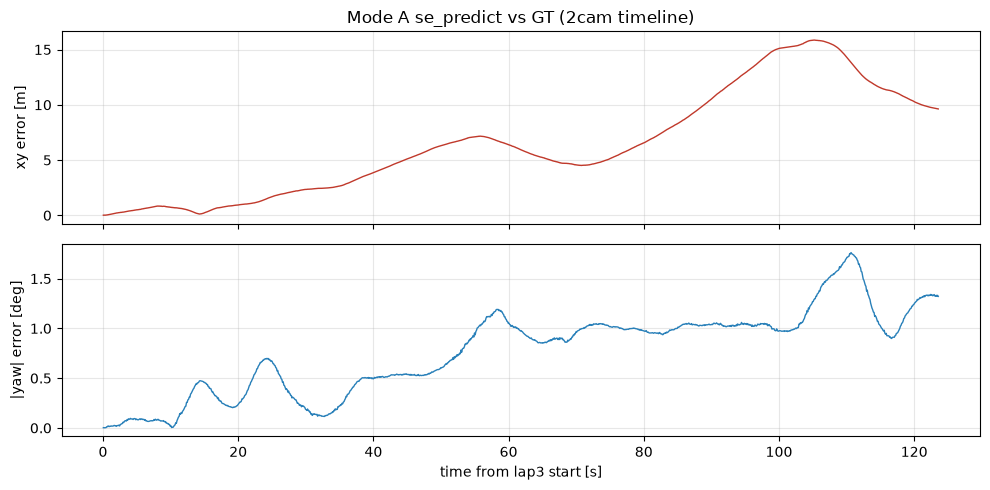

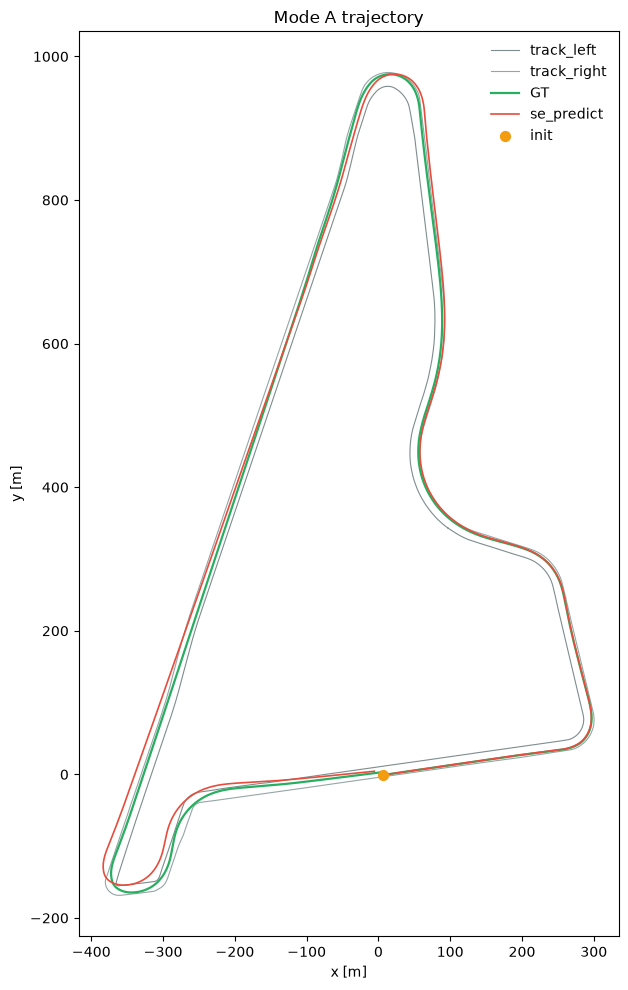

In [5]:
t_rel = (pred_a.timestamp_ns.to_numpy() - START_NS) * 1e-9

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(t_rel, err_a, color="#c0392b", lw=1.0)
axes[0].set_ylabel("xy error [m]")
axes[0].set_title("Mode A se_predict vs GT (2cam timeline)")
axes[0].grid(True, alpha=0.3)
axes[1].plot(t_rel, np.abs(yaw_a), color="#2980b9", lw=1.0)
axes[1].set_ylabel("|yaw| error [deg]")
axes[1].set_xlabel("time from lap3 start [s]")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_A / "err_vs_time.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.8, label="track_left")
ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.8, label="track_right")
ax.plot(gt_a.x, gt_a.y, color="#27ae60", lw=1.6, label="GT")
ax.plot(pred_a.x, pred_a.y, color="#e74c3c", lw=1.2, label="se_predict")
ax.scatter([x0], [y0], c="#f39c12", s=50, zorder=5, label="init")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Mode A trajectory")
ax.legend(loc="best", frameon=False)
fig.tight_layout()
fig.savefig(OUT_A / "traj_vs_gt.png", dpi=140, bbox_inches="tight")
plt.show()


## 4. Mode B — EKF + 两相机（fr/rl）sync / 外推 / se2 + \(R(s)\)


In [6]:
pred_b, sim_b = run_mode_b_ekf(
    se,
    buckets_2,
    cfg,
    x0=x0,
    y0=y0,
    yaw0=yaw0,
    t0_ns=t0,
    sigma_of_s_fn=sigma_of_s,
    track_line=track_line,
    cams=CAMS_2,
)
gt_b = interp_gt(gt_all, pred_b.timestamp_ns.to_numpy())
err_b = np.hypot(pred_b.x - gt_b.x, pred_b.y - gt_b.y)
yaw_b = np.degrees(np.arctan2(np.sin(pred_b.yaw - gt_b.yaw), np.cos(pred_b.yaw - gt_b.yaw)))

sub_b = OUT_B / "submission.csv"
write_submission(pred_b, sub_b)
sim_b.to_csv(OUT_B / "sim" / "ekf_sim.csv", index=False)
print("wrote", sub_b, "n=", len(pred_b), "update_rate=", f"{sim_b.updated.mean()*100:.1f}%")
print("xy RMSE", float(np.sqrt(np.mean(err_b**2))), "median", float(np.median(err_b)))

eval_b = run_evaluate(sub_b, GT_LAP)
print(eval_b)

met_b = metrics_vs_gt(pred_b, gt_b)
pd.Series(met_b).to_csv(OUT_B / "metrics_official.csv", header=["value"])
print(pd.Series(met_b).round(4))


wrote /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3_2cam_fr_rl/ekf_cam_2cam/submission.csv n= 1236 update_rate= 96.1%
xy RMSE 1.2942493272167606 median 0.6495027202864112
poses submitted        1236   evaluated 1236
coverage (1 s bins)    100.0 %   (>= 90 % to be ranked)
position RMSE  [m]     1.294   <- SCORE (lower is better)
position median/p95    0.650 / 2.458
lateral RMSE   [m]     0.665
longitudinal RMSE [m]  1.111
yaw RMSE     [deg]     0.431
within 0.25 m          6.8 %
within 0.50 m          33.7 %
within 1.00 m          66.1 %

n_query           1236.0000
n_success         1236.0000
success_rate_%     100.0000
pos_rmse_xy_m        1.2942
lat_rmse_m           0.6647
lon_rmse_m           1.1105
yaw_rmse_deg         0.4307
within_1m_%         66.1003
pos_median_m         0.6495
pos_p95_m            2.4575
pos_rmse_sn_m        1.2604
s_rmse_m             1.0455
n_rmse_m             0.7041
track_lap_m       2976.8753
dtype: float64


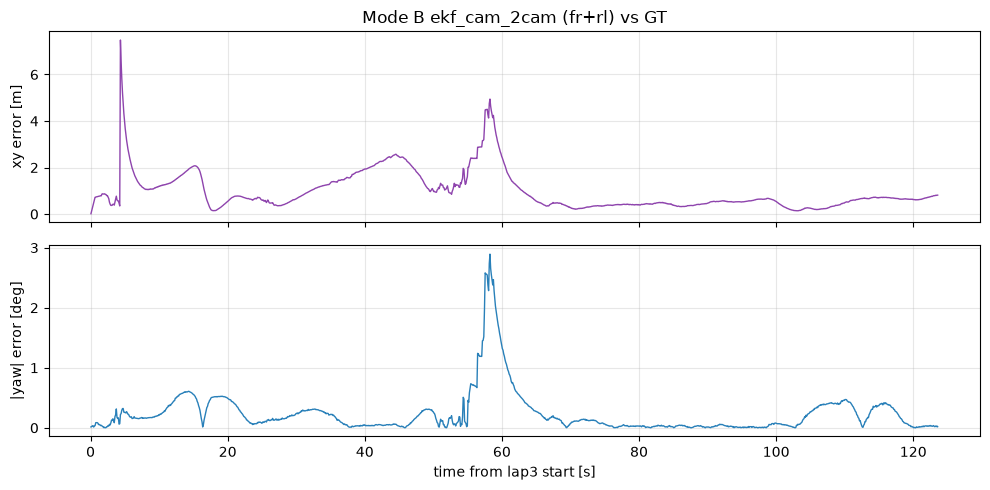

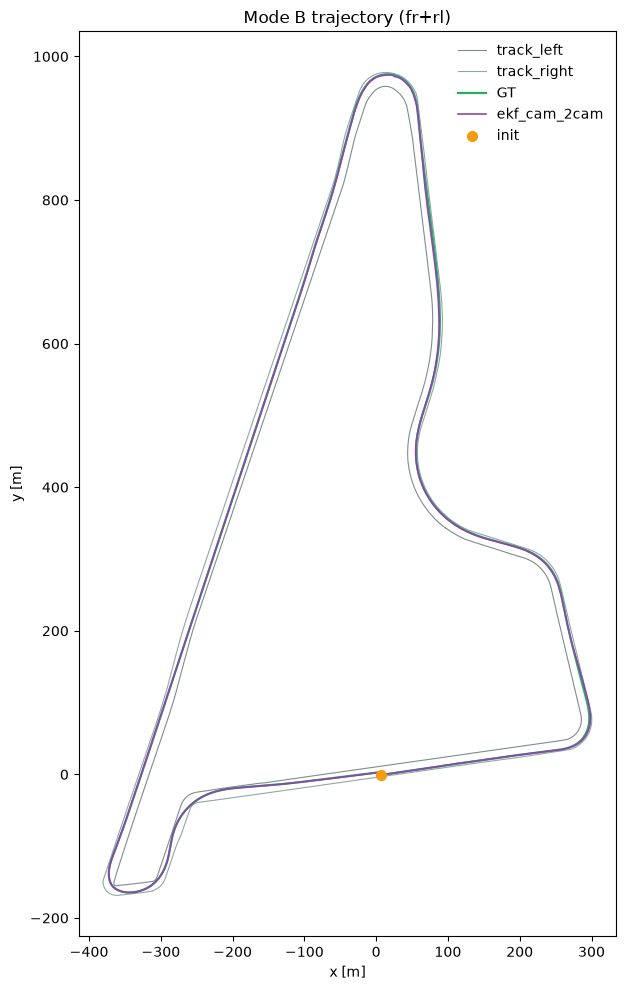

In [7]:
t_rel_b = (pred_b.timestamp_ns.to_numpy() - START_NS) * 1e-9

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(t_rel_b, err_b, color="#8e44ad", lw=1.0)
axes[0].set_ylabel("xy error [m]")
axes[0].set_title("Mode B ekf_cam_2cam (fr+rl) vs GT")
axes[0].grid(True, alpha=0.3)
axes[1].plot(t_rel_b, np.abs(yaw_b), color="#2980b9", lw=1.0)
axes[1].set_ylabel("|yaw| error [deg]")
axes[1].set_xlabel("time from lap3 start [s]")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_B / "err_vs_time.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.8, label="track_left")
ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.8, label="track_right")
ax.plot(gt_b.x, gt_b.y, color="#27ae60", lw=1.6, label="GT")
ax.plot(pred_b.x, pred_b.y, color="#8e44ad", lw=1.2, label="ekf_cam_2cam")
ax.scatter([x0], [y0], c="#f39c12", s=50, zorder=5, label="init")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Mode B trajectory (fr+rl)")
ax.legend(loc="best", frameon=False)
fig.tight_layout()
fig.savefig(OUT_B / "traj_vs_gt.png", dpi=140, bbox_inches="tight")
plt.show()


## 5. 两相机 vs 三相机离线 se2 融合

| mode | 相机 | 说明 |
|---|---|---|
| `fused_se2_2cam` | fr, rl | nearest-stamp ω 加权 SE(2) |
| `fused_se2_3cam` | r, fr, rl | 同算法，多 fr |


In [8]:
def metrics_from_fuse_df(df: pd.DataFrame) -> dict:
    ok = df["ok"].astype(bool).to_numpy()
    met = qde.compute_camloc_metrics(
        stamps_ns=df["stamp_ns"].to_numpy(),
        gt_xy=np.column_stack([df["gt_x"], df["gt_y"]]),
        gt_yaw=df["gt_yaw"].to_numpy(float),
        pred_xy=np.column_stack([df["pred_x"], df["pred_y"]]),
        pred_yaw=df["pred_yaw"].to_numpy(float),
        ok=ok,
    )
    return met, ok

df_f2 = fuse_loc_tables_se2(tables_2, ref_camera="fr")
df_f3 = fuse_loc_tables_se2(tables_3, ref_camera="r")
df_f2.to_csv(OUT_F2 / "errors_se2.csv", index=False)
df_f3.to_csv(OUT_F3 / "errors_se2.csv", index=False)
# also mirror 3cam under sfm outputs for consistency
fuse3_dir = qde.SFM_OUT / f"loc_lap{LAP}_fused"
fuse3_dir.mkdir(parents=True, exist_ok=True)
if not (fuse3_dir / "errors_se2.csv").is_file():
    df_f3.to_csv(fuse3_dir / "errors_se2.csv", index=False)

met_f2, ok_f2 = metrics_from_fuse_df(df_f2)
met_f3, ok_f3 = metrics_from_fuse_df(df_f3)
met_f2["mode"] = "fused_se2_2cam"
met_f3["mode"] = "fused_se2_3cam"
met_a["mode"] = "se_predict"
met_b["mode"] = "ekf_cam_2cam"

print("fused_2cam ok%", ok_f2.mean() * 100, "fused_3cam ok%", ok_f3.mean() * 100)
print("2cam", {k: round(met_f2[k], 3) for k in ("pos_rmse_xy_m", "within_1m_%", "yaw_rmse_deg")})
print("3cam", {k: round(met_f3[k], 3) for k in ("pos_rmse_xy_m", "within_1m_%", "yaw_rmse_deg")})


fused_2cam ok% 96.11650485436894 fused_3cam ok% 96.43724696356276
2cam {'pos_rmse_xy_m': 4.414, 'within_1m_%': 73.058, 'yaw_rmse_deg': 0.854}
3cam {'pos_rmse_xy_m': 4.424, 'within_1m_%': 72.713, 'yaw_rmse_deg': 0.874}


## 6. metrics_official：SE / 2cam 融合 / 3cam 融合 / EKF(2cam)

| mode | 来源 |
|---|---|
| `se_predict` | Mode A |
| `fused_se2_2cam` | fr+rl 离线 se2 |
| `fused_se2_3cam` | r+fr+rl 离线 se2 |
| `ekf_cam_2cam` | Mode B（fr+rl） |


=== metrics_official ===
          mode  n_query  n_success  success_rate_%  pos_rmse_xy_m  lat_rmse_m  lon_rmse_m  pos_rmse_sn_m  s_rmse_m  n_rmse_m  yaw_rmse_deg  within_1m_%  pos_median_m  pos_p95_m
    se_predict     1236       1236         100.000          8.024       6.174       5.125          7.960     5.110     6.103         0.876       16.667         5.707     15.299
fused_se2_2cam     1236       1188          96.117          4.414       2.285       3.776          4.366     3.666     2.371         0.854       73.058         0.336      8.921
fused_se2_3cam     1235       1191          96.437          4.424       2.275       3.794          4.363     3.664     2.370         0.874       72.713         0.367      8.893
  ekf_cam_2cam     1236       1236         100.000          1.294       0.665       1.111          1.260     1.045     0.704         0.431       66.100         0.650      2.458
wrote /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3_2cam_fr_rl/compare/metrics_o

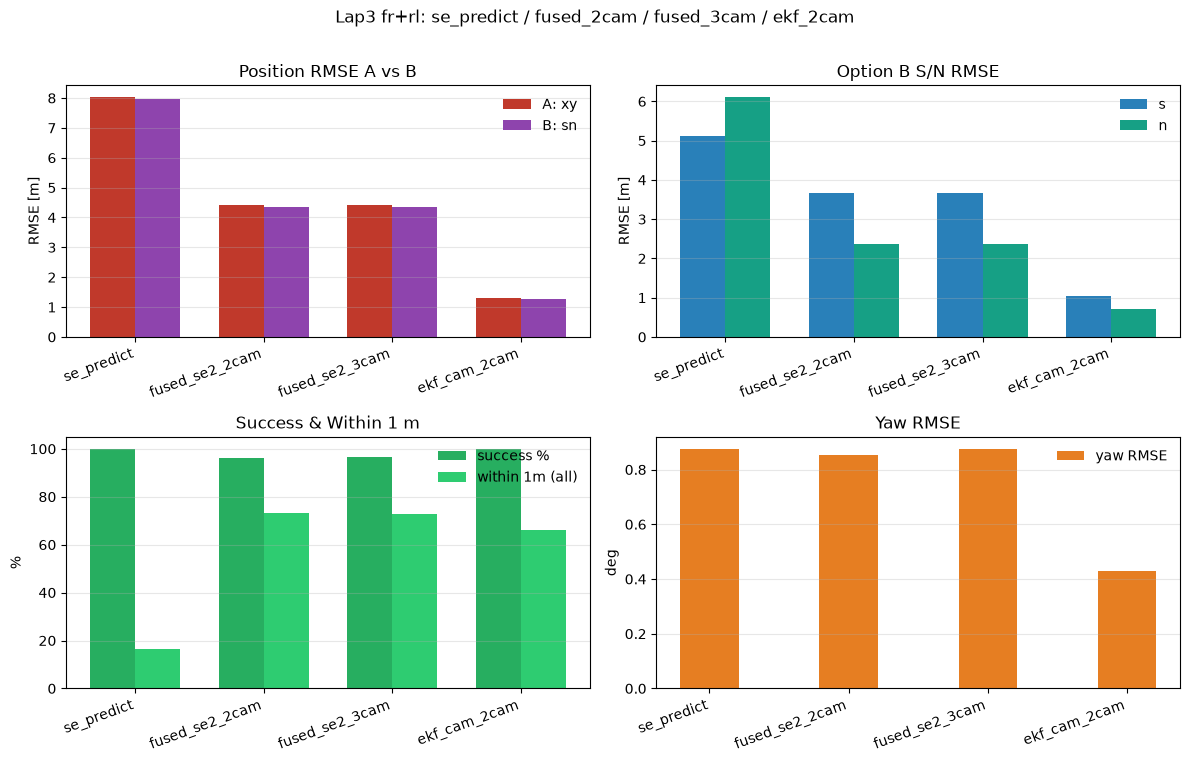

saved /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3_2cam_fr_rl/compare/fuse_2cam_vs_3cam.png


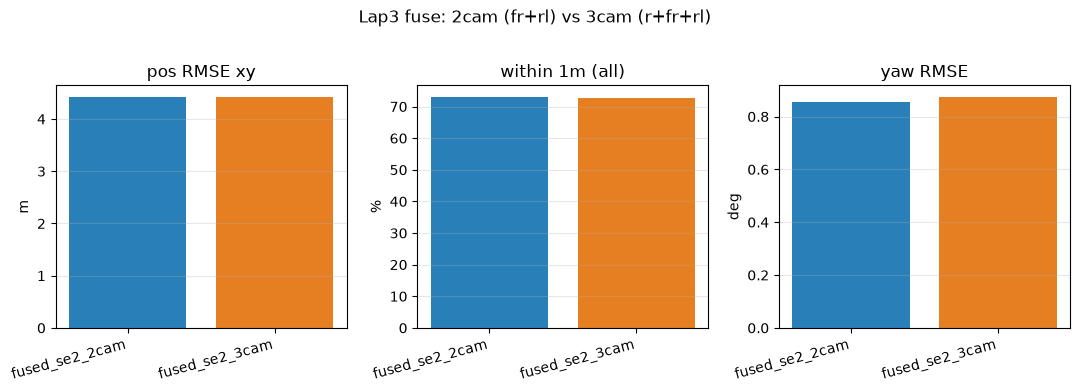

In [9]:
METRIC_COLS = [
    "mode",
    "n_query",
    "n_success",
    "success_rate_%",
    "pos_rmse_xy_m",
    "lat_rmse_m",
    "lon_rmse_m",
    "pos_rmse_sn_m",
    "s_rmse_m",
    "n_rmse_m",
    "yaw_rmse_deg",
    "within_1m_%",
    "pos_median_m",
    "pos_p95_m",
]

mdf = pd.DataFrame([met_a, met_f2, met_f3, met_b])
mdf = mdf[[c for c in METRIC_COLS if c in mdf.columns]]
order = {"se_predict": 0, "fused_se2_2cam": 1, "fused_se2_3cam": 2, "ekf_cam_2cam": 3}
mdf = mdf.sort_values("mode", key=lambda s: s.map(order)).reset_index(drop=True)

off_path = OUT_C / "metrics_official.csv"
mdf.to_csv(off_path, index=False)
mdf.to_csv(OUT_C / "metrics_compare.csv", index=False)

print("=== metrics_official ===")
print(mdf.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("wrote", off_path)

# dedicated 2cam vs 3cam fuse table
fuse_cmp = mdf[mdf["mode"].isin(["fused_se2_2cam", "fused_se2_3cam"])].reset_index(drop=True)
fuse_cmp.to_csv(OUT_C / "fuse_2cam_vs_3cam.csv", index=False)
print("\n=== 2cam vs 3cam fuse ===")
print(fuse_cmp[["mode", "n_success", "success_rate_%", "pos_rmse_xy_m", "pos_rmse_sn_m",
                "yaw_rmse_deg", "within_1m_%"]].to_string(index=False, float_format=lambda x: f"{x:.3f}"))

modes = mdf["mode"].tolist()
x = np.arange(len(modes))
w = 0.35
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

ax = axes[0, 0]
ax.bar(x - w / 2, mdf["pos_rmse_xy_m"], w, label="A: xy", color="#c0392b")
ax.bar(x + w / 2, mdf["pos_rmse_sn_m"], w, label="B: sn", color="#8e44ad")
ax.set_xticks(x); ax.set_xticklabels(modes, rotation=20, ha="right")
ax.set_ylabel("RMSE [m]"); ax.set_title("Position RMSE A vs B")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

ax = axes[0, 1]
ax.bar(x - w / 2, mdf["s_rmse_m"], w, label="s", color="#2980b9")
ax.bar(x + w / 2, mdf["n_rmse_m"], w, label="n", color="#16a085")
ax.set_xticks(x); ax.set_xticklabels(modes, rotation=20, ha="right")
ax.set_ylabel("RMSE [m]"); ax.set_title("Option B S/N RMSE")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

ax = axes[1, 0]
ax.bar(x - w / 2, mdf["success_rate_%"], w, label="success %", color="#27ae60")
ax.bar(x + w / 2, mdf["within_1m_%"], w, label="within 1m (all)", color="#2ecc71")
ax.set_xticks(x); ax.set_xticklabels(modes, rotation=20, ha="right")
ax.set_ylabel("%"); ax.set_title("Success & Within 1 m")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

ax = axes[1, 1]
ax.bar(x, mdf["yaw_rmse_deg"], w * 1.2, label="yaw RMSE", color="#e67e22")
ax.set_xticks(x); ax.set_xticklabels(modes, rotation=20, ha="right")
ax.set_ylabel("deg"); ax.set_title("Yaw RMSE")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

fig.suptitle("Lap3 fr+rl: se_predict / fused_2cam / fused_3cam / ekf_2cam", y=1.01)
fig.tight_layout()
fig.savefig(OUT_C / "metrics_official.png", dpi=150, bbox_inches="tight")
print("saved", OUT_C / "metrics_official.png")
plt.show()

# focused 2 vs 3 fuse bars
xf = np.arange(len(fuse_cmp))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].bar(xf, fuse_cmp["pos_rmse_xy_m"], color=["#2980b9", "#e67e22"])
axes[0].set_xticks(xf); axes[0].set_xticklabels(fuse_cmp["mode"], rotation=15, ha="right")
axes[0].set_ylabel("m"); axes[0].set_title("pos RMSE xy"); axes[0].grid(True, axis="y", alpha=0.3)
axes[1].bar(xf, fuse_cmp["within_1m_%"], color=["#2980b9", "#e67e22"])
axes[1].set_xticks(xf); axes[1].set_xticklabels(fuse_cmp["mode"], rotation=15, ha="right")
axes[1].set_ylabel("%"); axes[1].set_title("within 1m (all)"); axes[1].grid(True, axis="y", alpha=0.3)
axes[2].bar(xf, fuse_cmp["yaw_rmse_deg"], color=["#2980b9", "#e67e22"])
axes[2].set_xticks(xf); axes[2].set_xticklabels(fuse_cmp["mode"], rotation=15, ha="right")
axes[2].set_ylabel("deg"); axes[2].set_title("yaw RMSE"); axes[2].grid(True, axis="y", alpha=0.3)
fig.suptitle("Lap3 fuse: 2cam (fr+rl) vs 3cam (r+fr+rl)", y=1.02)
fig.tight_layout()
fig.savefig(OUT_C / "fuse_2cam_vs_3cam.png", dpi=150, bbox_inches="tight")
print("saved", OUT_C / "fuse_2cam_vs_3cam.png")
plt.show()


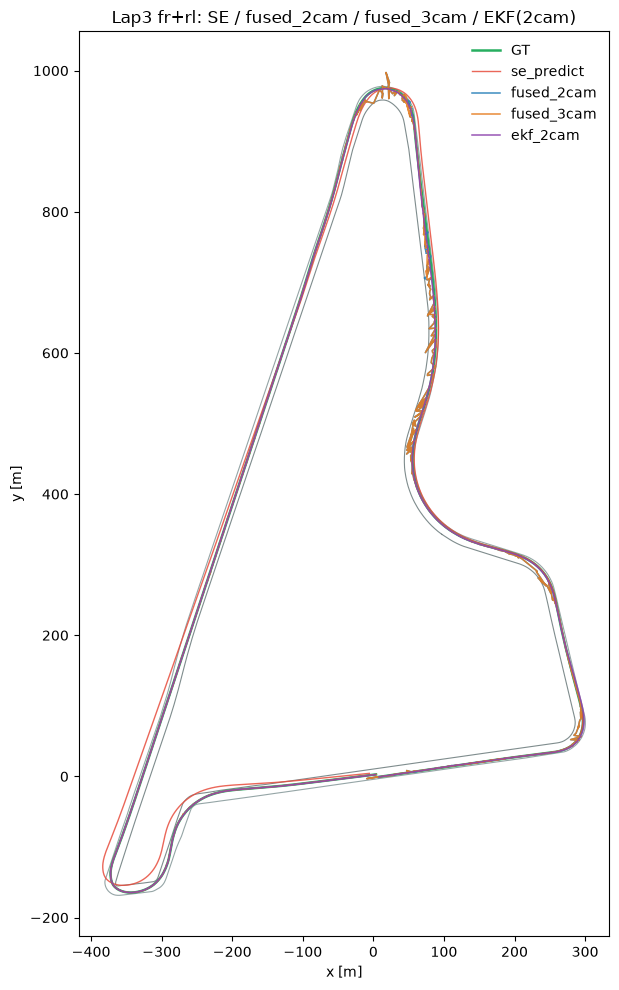

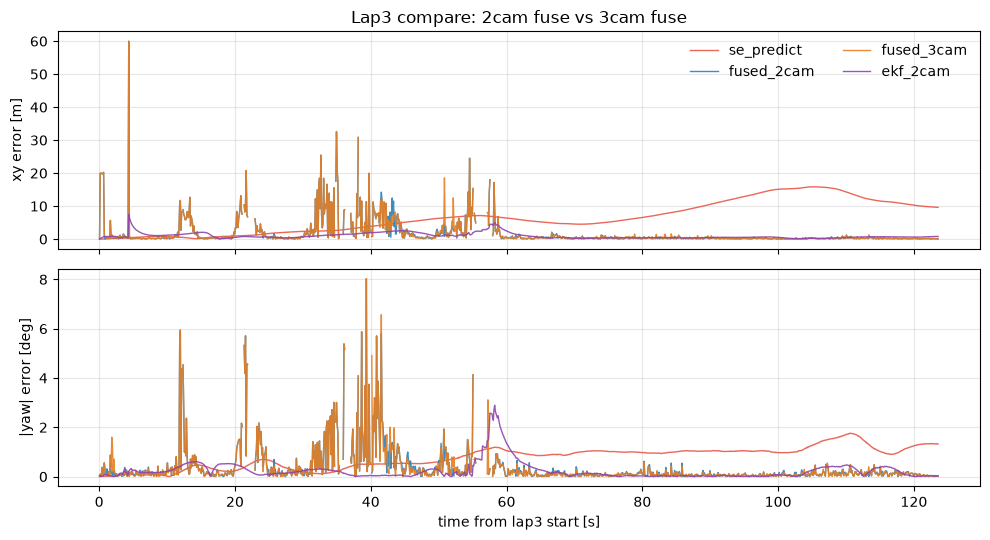

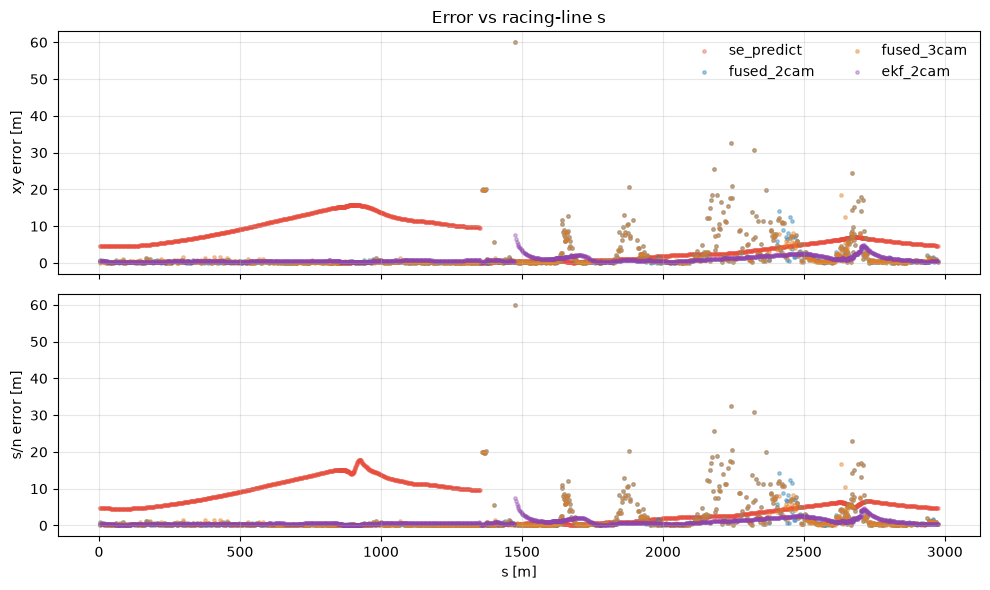

done. outputs under /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3_2cam_fr_rl
          mode  pos_rmse_xy_m  pos_rmse_sn_m  yaw_rmse_deg  within_1m_%  success_rate_%
    se_predict          8.024          7.960         0.876       16.667         100.000
fused_se2_2cam          4.414          4.366         0.854       73.058          96.117
fused_se2_3cam          4.424          4.363         0.874       72.713          96.437
  ekf_cam_2cam          1.294          1.260         0.431       66.100         100.000


In [10]:
# trajectories
pred_f2 = pd.DataFrame({
    "timestamp_ns": df_f2["stamp_ns"].to_numpy(),
    "x": df_f2["pred_x"].to_numpy(float),
    "y": df_f2["pred_y"].to_numpy(float),
    "yaw": df_f2["pred_yaw"].to_numpy(float),
})
pred_f3 = pd.DataFrame({
    "timestamp_ns": df_f3["stamp_ns"].to_numpy(),
    "x": df_f3["pred_x"].to_numpy(float),
    "y": df_f3["pred_y"].to_numpy(float),
    "yaw": df_f3["pred_yaw"].to_numpy(float),
})
pred_f2_ok = pred_f2.loc[ok_f2].reset_index(drop=True)
pred_f3_ok = pred_f3.loc[ok_f3].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.8)
ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.8)
ax.plot(gt_a.x, gt_a.y, color="#27ae60", lw=1.8, label="GT")
ax.plot(pred_a.x, pred_a.y, color="#e74c3c", lw=1.0, label="se_predict", alpha=0.85)
ax.plot(pred_f2_ok.x, pred_f2_ok.y, color="#2980b9", lw=1.1, label="fused_2cam", alpha=0.9)
ax.plot(pred_f3_ok.x, pred_f3_ok.y, color="#e67e22", lw=1.1, label="fused_3cam", alpha=0.9)
ax.plot(pred_b.x, pred_b.y, color="#8e44ad", lw=1.1, label="ekf_2cam", alpha=0.9)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Lap3 fr+rl: SE / fused_2cam / fused_3cam / EKF(2cam)")
ax.legend(loc="best", frameon=False)
fig.tight_layout()
fig.savefig(OUT_C / "traj_vs_gt.png", dpi=140, bbox_inches="tight")
plt.show()

err_f2 = np.full(len(df_f2), np.nan)
err_f2[ok_f2] = np.hypot(
    df_f2.loc[ok_f2, "pred_x"].to_numpy(float) - df_f2.loc[ok_f2, "gt_x"].to_numpy(float),
    df_f2.loc[ok_f2, "pred_y"].to_numpy(float) - df_f2.loc[ok_f2, "gt_y"].to_numpy(float),
)
err_f3 = np.full(len(df_f3), np.nan)
err_f3[ok_f3] = np.hypot(
    df_f3.loc[ok_f3, "pred_x"].to_numpy(float) - df_f3.loc[ok_f3, "gt_x"].to_numpy(float),
    df_f3.loc[ok_f3, "pred_y"].to_numpy(float) - df_f3.loc[ok_f3, "gt_y"].to_numpy(float),
)
t_rel_f2 = (df_f2["stamp_ns"].to_numpy() - START_NS) * 1e-9
t_rel_f3 = (df_f3["stamp_ns"].to_numpy() - START_NS) * 1e-9

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(t_rel, err_a, color="#e74c3c", lw=1.0, label="se_predict", alpha=0.85)
axes[0].plot(t_rel_f2, err_f2, color="#2980b9", lw=1.0, label="fused_2cam", alpha=0.9)
axes[0].plot(t_rel_f3, err_f3, color="#e67e22", lw=1.0, label="fused_3cam", alpha=0.9)
axes[0].plot(t_rel_b, err_b, color="#8e44ad", lw=1.0, label="ekf_2cam", alpha=0.9)
axes[0].set_ylabel("xy error [m]")
axes[0].legend(frameon=False, ncol=2)
axes[0].grid(True, alpha=0.3)
axes[0].set_title("Lap3 compare: 2cam fuse vs 3cam fuse")
yaw_f2 = np.full(len(df_f2), np.nan)
yaw_f2[ok_f2] = np.degrees(np.arctan2(
    np.sin(df_f2.loc[ok_f2, "pred_yaw"].to_numpy(float) - df_f2.loc[ok_f2, "gt_yaw"].to_numpy(float)),
    np.cos(df_f2.loc[ok_f2, "pred_yaw"].to_numpy(float) - df_f2.loc[ok_f2, "gt_yaw"].to_numpy(float)),
))
yaw_f3 = np.full(len(df_f3), np.nan)
yaw_f3[ok_f3] = np.degrees(np.arctan2(
    np.sin(df_f3.loc[ok_f3, "pred_yaw"].to_numpy(float) - df_f3.loc[ok_f3, "gt_yaw"].to_numpy(float)),
    np.cos(df_f3.loc[ok_f3, "pred_yaw"].to_numpy(float) - df_f3.loc[ok_f3, "gt_yaw"].to_numpy(float)),
))
axes[1].plot(t_rel, np.abs(yaw_a), color="#e74c3c", lw=1.0, alpha=0.85)
axes[1].plot(t_rel_f2, np.abs(yaw_f2), color="#2980b9", lw=1.0, alpha=0.9)
axes[1].plot(t_rel_f3, np.abs(yaw_f3), color="#e67e22", lw=1.0, alpha=0.9)
axes[1].plot(t_rel_b, np.abs(yaw_b), color="#8e44ad", lw=1.0, alpha=0.9)
axes[1].set_ylabel("|yaw| error [deg]")
axes[1].set_xlabel("time from lap3 start [s]")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_C / "err_vs_time.png", dpi=140, bbox_inches="tight")
plt.show()

def errs_vs_s(pred, gt_at, ok_mask=None):
    if ok_mask is None:
        ok_mask = np.ones(len(pred), dtype=bool)
    ts = pred["timestamp_ns"].to_numpy(dtype=np.int64)[ok_mask]
    gx = gt_at["x"].to_numpy()[ok_mask] if "x" in gt_at.columns else gt_at.x.to_numpy()[ok_mask]
    gy = gt_at["y"].to_numpy()[ok_mask] if "y" in gt_at.columns else gt_at.y.to_numpy()[ok_mask]
    gyaw = gt_at["yaw"].to_numpy()[ok_mask] if "yaw" in gt_at.columns else gt_at.yaw.to_numpy()[ok_mask]
    px = pred["x"].to_numpy()[ok_mask]
    py = pred["y"].to_numpy()[ok_mask]
    pyaw = pred["yaw"].to_numpy()[ok_mask]
    sg, ng, _, _ = track_line.xy_to_sn(gx, gy, gyaw, ts)
    sp, np_, _, _ = track_line.xy_to_sn(px, py, pyaw, ts)
    lap = float(track_line.lap)
    sg_u = np.unwrap(sg, period=lap)
    ds = (sp - sg_u + lap / 2) % lap - lap / 2
    dn = np_ - ng
    e_xy = np.hypot(px - gx, py - gy)
    return sg, e_xy, np.hypot(ds, dn)

s_a, e_a_s, e_sn_a = errs_vs_s(pred_a, gt_a)
s_b, e_b_s, e_sn_b = errs_vs_s(pred_b, gt_b)
gt_f2_full = pd.DataFrame({"x": df_f2["gt_x"].to_numpy(float), "y": df_f2["gt_y"].to_numpy(float), "yaw": df_f2["gt_yaw"].to_numpy(float)})
gt_f3_full = pd.DataFrame({"x": df_f3["gt_x"].to_numpy(float), "y": df_f3["gt_y"].to_numpy(float), "yaw": df_f3["gt_yaw"].to_numpy(float)})
s_f2, e_f2_s, e_sn_f2 = errs_vs_s(pred_f2, gt_f2_full, ok_f2)
s_f3, e_f3_s, e_sn_f3 = errs_vs_s(pred_f3, gt_f3_full, ok_f3)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].scatter(s_a, e_a_s, s=6, c="#e74c3c", alpha=0.35, label="se_predict")
axes[0].scatter(s_f2, e_f2_s, s=6, c="#2980b9", alpha=0.4, label="fused_2cam")
axes[0].scatter(s_f3, e_f3_s, s=6, c="#e67e22", alpha=0.4, label="fused_3cam")
axes[0].scatter(s_b, e_b_s, s=6, c="#8e44ad", alpha=0.35, label="ekf_2cam")
axes[0].set_ylabel("xy error [m]")
axes[0].legend(frameon=False, ncol=2)
axes[0].grid(True, alpha=0.3)
axes[0].set_title("Error vs racing-line s")
axes[1].scatter(s_a, e_sn_a, s=6, c="#e74c3c", alpha=0.35)
axes[1].scatter(s_f2, e_sn_f2, s=6, c="#2980b9", alpha=0.4)
axes[1].scatter(s_f3, e_sn_f3, s=6, c="#e67e22", alpha=0.4)
axes[1].scatter(s_b, e_sn_b, s=6, c="#8e44ad", alpha=0.35)
axes[1].set_ylabel("s/n error [m]")
axes[1].set_xlabel("s [m]")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_C / "err_vs_s.png", dpi=140, bbox_inches="tight")
plt.show()

print("done. outputs under", OUT)
print(mdf[["mode", "pos_rmse_xy_m", "pos_rmse_sn_m", "yaw_rmse_deg", "within_1m_%", "success_rate_%"]].to_string(
    index=False, float_format=lambda x: f"{x:.3f}"))


## 输出清单

```
query-demo/outputs/lap3_2cam_fr_rl/
  gt_lap3.csv
  se_predict/
  ekf_cam_2cam/          # fr+rl EKF
  fused_se2_2cam/errors_se2.csv
  fused_se2_3cam/errors_se2.csv
  compare/
    metrics_official.csv / .png
    fuse_2cam_vs_3cam.csv / .png
    traj_vs_gt.png, err_vs_time.png, err_vs_s.png
```
